# Regularization: Taming Overfitting

In the previous notebook, we discovered a critical problem: **overfitting**. When we used high-degree polynomials (like degree 16), our model achieved nearly perfect performance on training data but failed miserably on new, unseen data. The model memorized noise instead of learning genuine patterns.

We learned to *detect* overfitting using validation sets. But how do we *prevent* it?

This is where **regularization** comes in. Regularization modifies our learning algorithm to discourage overly complex models, keeping them from chasing every fluctuation in the training data.

In this notebook, we'll explore:
- **Why** complex models overfit and what makes them "too flexible"
- **How** regularization controls model complexity
- **Ridge Regression (L2)**: Shrinking all coefficients smoothly
- **Lasso Regression (L1)**: Forcing some coefficients to exactly zero
- **How to choose** the regularization strength

Let's see how to keep our models honest!

## <a id='toc1_'></a>[The Problem: When Flexibility Becomes a Curse](#toc0_)

Let's recreate the overfitting scenario from our previous notebook to see exactly what goes wrong.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# Recreate the study hours dataset
np.random.seed(141)
n_points = 100
study_hours = np.linspace(0, 30, n_points)
base_scores = 25 + 6 * study_hours - 0.15 * study_hours**2
noise = np.random.normal(0, 4, n_points)
test_scores = np.clip(base_scores + noise, 0, 100)

# Split data
X = study_hours.reshape(-1, 1)
y = test_scores

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Normalize
X_mean, X_std = np.mean(X_train), np.std(X_train)
X_train_norm = (X_train - X_mean) / X_std
X_val_norm = (X_val - X_mean) / X_std

print(f"Dataset: {len(X_train)} training, {len(X_val)} validation, {len(X_test)} test samples")

Dataset: 60 training, 20 validation, 20 test samples


In [3]:
# Fit a high-degree polynomial (degree 12) without regularization
degree = 12
poly = PolynomialFeatures(degree=degree)
X_train_poly = poly.fit_transform(X_train_norm)
X_val_poly = poly.transform(X_val_norm)

# Train without regularization
model_overfit = LinearRegression()
model_overfit.fit(X_train_poly, y_train)

# Evaluate
y_train_pred = model_overfit.predict(X_train_poly)
y_val_pred = model_overfit.predict(X_val_poly)

train_mse = mean_squared_error(y_train, y_train_pred)
val_mse = mean_squared_error(y_val, y_val_pred)

print(f"Degree {degree} Polynomial (No Regularization):")
print(f"  Training MSE: {train_mse:.2f}")
print(f"  Validation MSE: {val_mse:.2f}")
print(f"  Gap: {val_mse - train_mse:.2f} ← Signs of overfitting!")
print(f"\nLearned coefficients (β values):")
print(f"  Max coefficient magnitude: {np.max(np.abs(model_overfit.coef_)):.2e}")
print(f"  Min coefficient magnitude: {np.min(np.abs(model_overfit.coef_)):.2e}")

Degree 12 Polynomial (No Regularization):
  Training MSE: 19.11
  Validation MSE: 21.67
  Gap: 2.56 ← Signs of overfitting!

Learned coefficients (β values):
  Max coefficient magnitude: 1.49e+02
  Min coefficient magnitude: 0.00e+00


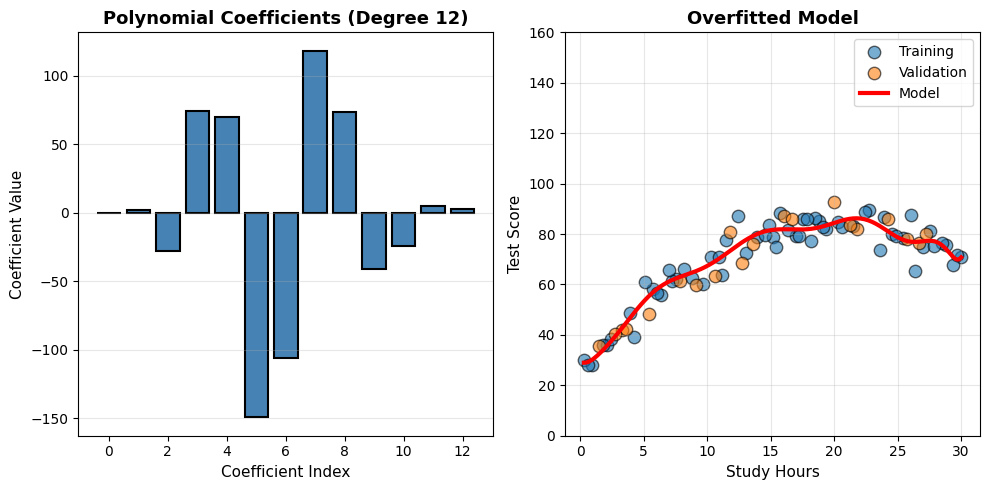

In [4]:
# Visualize the coefficients
plt.figure(figsize=(10, 5))
coefficients = model_overfit.coef_

plt.subplot(1, 2, 1)
plt.bar(range(len(coefficients)), coefficients, color='steelblue', edgecolor='black', linewidth=1.5)
plt.xlabel('Coefficient Index', fontsize=11)
plt.ylabel('Coefficient Value', fontsize=11)
plt.title(f'Polynomial Coefficients (Degree {degree})', fontsize=13, fontweight='bold')
plt.grid(True, alpha=0.3, axis='y')

# Visualize the overfitted model
plt.subplot(1, 2, 2)
X_plot = np.linspace(X_train.min(), X_train.max(), 200).reshape(-1, 1)
X_plot_norm = (X_plot - X_mean) / X_std
X_plot_poly = poly.transform(X_plot_norm)
y_plot = model_overfit.predict(X_plot_poly)

plt.scatter(X_train, y_train, alpha=0.6, s=80, label='Training', edgecolors='black', linewidths=1)
plt.scatter(X_val, y_val, alpha=0.6, s=80, label='Validation', edgecolors='black', linewidths=1)
plt.plot(X_plot, y_plot, 'r-', linewidth=3, label='Model')
plt.xlabel('Study Hours', fontsize=11)
plt.ylabel('Test Score', fontsize=11)
plt.title('Overfitted Model', fontsize=13, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim([0, 160])

plt.tight_layout()
plt.show()

**What's happening here?**

Notice the coefficient values in the left plot—they're **huge** and wildly varying! Some coefficients are enormous (positive or negative), allowing the polynomial to create dramatic wiggles to hit every training point.

The right plot shows the result: a model that:
- ✅ Fits training data extremely well (low training MSE)
- ❌ Makes unrealistic predictions (wild oscillations)
- ❌ Performs poorly on validation data (high validation MSE)

**The root cause:** The model has too much *flexibility*. With 12 degrees of freedom, it can twist and turn to memorize training noise. Those enormous coefficients enable extreme curvature.

**The insight:** If we could somehow *limit* how large these coefficients can grow, we'd force the model to be smoother and more generalizable. That's exactly what regularization does!

## <a id='toc2_'></a>[What is Regularization?](#toc0_)

### <a id='toc2_1_'></a>[The Core Idea](#toc0_)

Regularization is a technique that **penalizes model complexity** to prevent overfitting. Instead of just minimizing error on training data, we add a penalty for having large coefficients.

**The intuition:**
- Large coefficients → steep curves, dramatic changes, overfitting
- Small coefficients → gentle curves, smooth predictions, better generalization

Think of it like this: We're training a model, but we're also telling it, "Don't get too wild with those coefficients. Keep them reasonable."

**The trade-off:**
- **Without regularization:** Minimize training error at all costs → overfitting
- **With regularization:** Balance training error AND coefficient size → smoother model

It's like telling a student: "Do well on the practice tests, *but* don't memorize every single answer. Understand the concepts instead."

### <a id='toc2_2_'></a>[How It Works Mathematically](#toc0_)

Recall the ordinary least squares (OLS) objective for linear regression:

$$\text{Minimize: } \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

This just minimizes the squared errors between actual and predicted values.

**Regularization adds a penalty term:**

$$\text{Minimize: } \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 + \lambda \times \text{Penalty}(\beta)$$

Where:
- First term: **Training error** (how well we fit the data)
- Second term: **Complexity penalty** (how large the coefficients are)
- $\lambda$ (lambda): **Regularization strength** (how much we care about the penalty)

**The two parts:**

1. **Training error:** $\sum_{i=1}^{n} (y_i - \hat{y}_i)^2$
   - Measures fit to training data
   - Wants to be small

2. **Penalty term:** $\lambda \times \text{Penalty}(\beta)$
   - Measures coefficient magnitudes
   - Prevents coefficients from getting too large
   - $\lambda$ controls the trade-off

**The balancing act:**
- If $\lambda = 0$: No penalty, standard regression (risk overfitting)
- If $\lambda$ is small: Slight penalty, mostly focus on fit
- If $\lambda$ is large: Heavy penalty, forces small coefficients (risk underfitting)

The art of regularization is choosing the right $\lambda$!

## <a id='toc3_'></a>[Ridge Regression (L2 Regularization)](#toc0_)

Ridge regression is one of the most popular regularization techniques. It adds a penalty based on the **squared** coefficients.

### <a id='toc3_1_'></a>[The Formula](#toc0_)

**Ridge regression objective:**

$$\text{Minimize: } \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 + \lambda \sum_{j=1}^{p} \beta_j^2$$

Where:
- $\sum_{i=1}^{n} (y_i - \hat{y}_i)^2$: Training error (Mean Squared Error)
- $\lambda \sum_{j=1}^{p} \beta_j^2$: **L2 penalty** (sum of squared coefficients)
- $\lambda$: Regularization strength (higher = more penalty)
- $p$: Number of features

**Why squared coefficients?**
- Penalizes large coefficients more heavily than small ones
- A coefficient of 10 is penalized 100 times more than a coefficient of 1
- Creates **smooth, continuous shrinkage**—all coefficients get smaller, but none become exactly zero
- Mathematically convenient (has a closed-form solution)

**The effect:**
- Small $\lambda$: Coefficients stay relatively large → complex model
- Large $\lambda$: Coefficients shrink toward zero → simpler model
- All coefficients shrink proportionally, but smoothly (not to exactly zero)

### <a id='toc3_2_'></a>[Implementation with Scikit-Learn](#toc0_)

Scikit-learn makes Ridge regression easy with the `Ridge` class. Note that sklearn uses `alpha` as the parameter name instead of $\lambda$.

In [ ]:
from sklearn.linear_model import Ridge

# Use the same degree 12 polynomial features
degree = 12
poly = PolynomialFeatures(degree=degree)
X_train_poly = poly.fit_transform(X_train_norm) # fit_trans -> learn rule and apply
X_val_poly = poly.transform(X_val_norm) # apply rule

# Fit Ridge regression with moderate regularization
lambda_value = 3.0  # sklearn calls this 'alpha'
ridge_model = Ridge(alpha=lambda_value)
ridge_model.fit(X_train_poly, y_train)

# Evaluate
y_train_pred_ridge = ridge_model.predict(X_train_poly)
y_val_pred_ridge = ridge_model.predict(X_val_poly)

train_mse_ridge = mean_squared_error(y_train, y_train_pred_ridge)
val_mse_ridge = mean_squared_error(y_val, y_val_pred_ridge)

print(f"Ridge Regression (λ={lambda_value}, degree={degree}):")
print(f"  Training MSE: {train_mse_ridge:.2f}")
print(f"  Validation MSE: {val_mse_ridge:.2f}")
print(f"  Gap: {val_mse_ridge - train_mse_ridge:.2f}")
print(f"\nCoefficient magnitudes:")
print(f"  Max: {np.max(np.abs(ridge_model.coef_)):.2e}") # :.2f for regular decimal notation as opposed ot scientific
print(f"  Min: {np.min(np.abs(ridge_model.coef_)):.2e}")
print(f"\n✅ Much smaller coefficients and better generalization!")

Ridge Regression (λ=3.0, degree=12):
  Training MSE: 22.73
  Validation MSE: 29.03
  Gap: 6.30

Coefficient magnitudes:
  Max: 7.59e+00
  Min: 0.00e+00

✅ Much smaller coefficients and better generalization!


### <a id='toc3_3_'></a>[Visualizing Ridge's Effect](#toc0_)

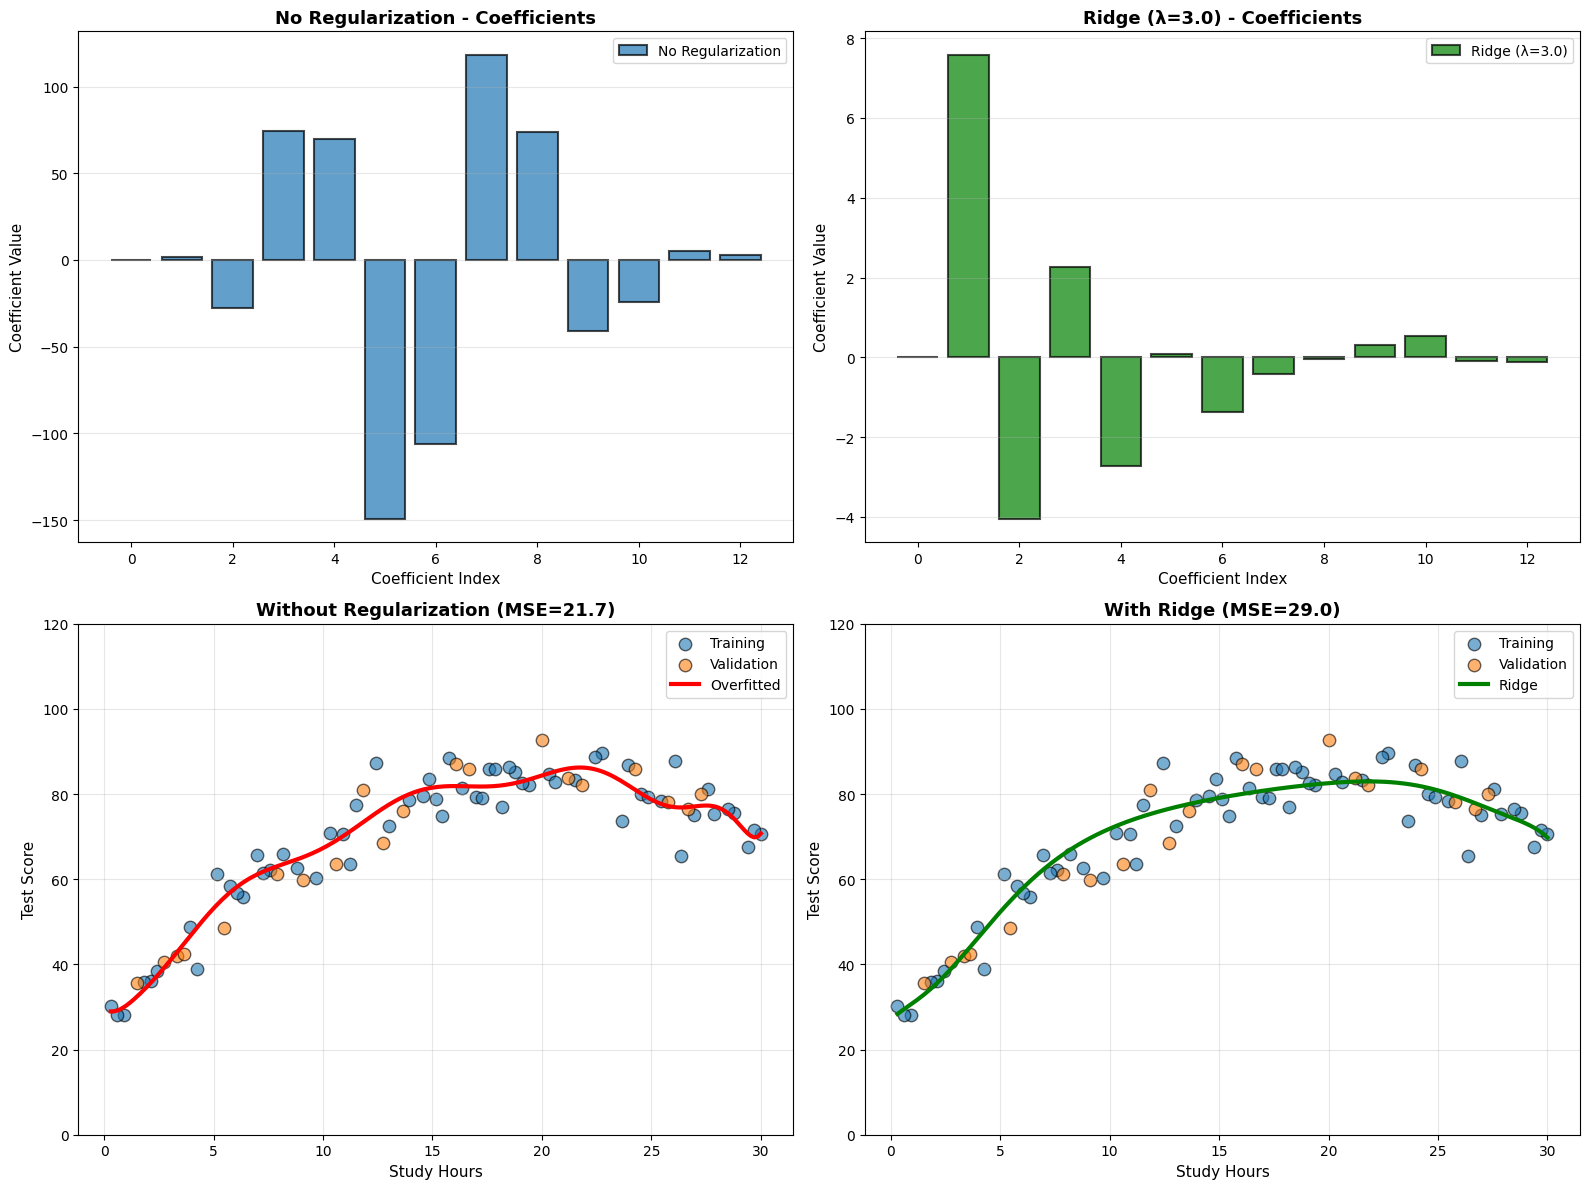

Notice how Ridge:
✓ Shrinks all coefficients (compare top plots)
✓ Creates smoother predictions (bottom plots)
✓ Better validation performance


In [6]:
# Compare coefficients: No regularization vs Ridge
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: No Regularization coefficients
axes[0, 0].bar(range(len(model_overfit.coef_)), 
			   model_overfit.coef_, 
			   alpha=0.7,
			   label='No Regularization',
			   edgecolor='black',
			   linewidth=1.5)

axes[0, 0].set_xlabel('Coefficient Index', fontsize=11)
axes[0, 0].set_ylabel('Coefficient Value', fontsize=11)
axes[0, 0].set_title('No Regularization - Coefficients', fontsize=13, fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3, axis='y')

# Plot 2: Ridge coefficients
axes[0, 1].bar(range(len(ridge_model.coef_)),
			   ridge_model.coef_, 
			   alpha=0.7,
			   label=f'Ridge (λ={lambda_value})',
			   color='green',
			   edgecolor='black',
			   linewidth=1.5)
			   
axes[0, 1].set_xlabel('Coefficient Index', fontsize=11)
axes[0, 1].set_ylabel('Coefficient Value', fontsize=11)
axes[0, 1].set_title(f'Ridge (λ={lambda_value}) - Coefficients', fontsize=13, fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Plot 3: Without regularization
X_plot = np.linspace(X_train.min(), X_train.max(), 200).reshape(-1, 1)
X_plot_norm = (X_plot - X_mean) / X_std
X_plot_poly = poly.transform(X_plot_norm)
y_plot_overfit = model_overfit.predict(X_plot_poly)

axes[1, 0].scatter(X_train, y_train, alpha=0.6, s=80, label='Training', edgecolors='black', linewidths=1)
axes[1, 0].scatter(X_val, y_val, alpha=0.6, s=80, label='Validation', edgecolors='black', linewidths=1)
axes[1, 0].plot(X_plot, y_plot_overfit, 'r-', linewidth=3, label='Overfitted')
axes[1, 0].set_xlabel('Study Hours', fontsize=11)
axes[1, 0].set_ylabel('Test Score', fontsize=11)
axes[1, 0].set_title(f'Without Regularization (MSE={val_mse:.1f})', fontsize=13, fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].set_ylim([0, 120])

# Plot 4: With Ridge
y_plot_ridge = ridge_model.predict(X_plot_poly)

axes[1, 1].scatter(X_train, y_train, alpha=0.6, s=80, label='Training', edgecolors='black', linewidths=1)
axes[1, 1].scatter(X_val, y_val, alpha=0.6, s=80, label='Validation', edgecolors='black', linewidths=1)
axes[1, 1].plot(X_plot, y_plot_ridge, 'g-', linewidth=3, label='Ridge')
axes[1, 1].set_xlabel('Study Hours', fontsize=11)
axes[1, 1].set_ylabel('Test Score', fontsize=11)
axes[1, 1].set_title(f'With Ridge (MSE={val_mse_ridge:.1f})', fontsize=13, fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].set_ylim([0, 120])

plt.tight_layout()
plt.show()

print("Notice how Ridge:")
print("✓ Shrinks all coefficients (compare top plots)")
print("✓ Creates smoother predictions (bottom plots)")
print("✓ Better validation performance")

## <a id='toc4_'></a>[Lasso Regression (L1 Regularization)](#toc0_)

Lasso (Least Absolute Shrinkage and Selection Operator) uses a different penalty: the **absolute value** of coefficients instead of their squares.

### <a id='toc4_1_'></a>[The Formula](#toc0_)

**Lasso regression objective:**

$$\text{Minimize: } \sum_{i=1}^{n} (y_i - \hat{y}_i)^2 + \lambda \sum_{j=1}^{p} |\beta_j|$$

Where:
- $\sum_{i=1}^{n} (y_i - \hat{y}_i)^2$: Training error (Mean Squared Error)
- $\lambda \sum_{j=1}^{p} |\beta_j|$: **L1 penalty** (sum of absolute values of coefficients)
- $\lambda$: Regularization strength

**Why absolute values?**
- Treats all coefficient sizes more equally (linear penalty, not quadratic)
- Has a special property: **Can force coefficients to become exactly zero**
- Performs **automatic feature selection**—eliminates irrelevant features
- Creates **sparse models** (many coefficients = 0)

**Ridge vs Lasso penalties:**
- **Ridge (L2):** $\beta^2$ → smooth shrinkage, keeps all features
- **Lasso (L1):** $|\beta|$ → aggressive shrinkage, eliminates features

**The effect:**
- Lasso not only shrinks coefficients but can eliminate them entirely
- Useful when you suspect many features are irrelevant
- Creates simpler, more interpretable models

### <a id='toc4_2_'></a>[Implementation with Scikit-Learn](#toc0_)

In [7]:
from sklearn.linear_model import Lasso

# Fit Lasso regression
lambda_value = 0.3  # sklearn calls this 'alpha'
lasso_model = Lasso(alpha=lambda_value, max_iter=100000)
lasso_model.fit(X_train_poly, y_train)

# Evaluate
y_train_pred_lasso = lasso_model.predict(X_train_poly)
y_val_pred_lasso = lasso_model.predict(X_val_poly)

train_mse_lasso = mean_squared_error(y_train, y_train_pred_lasso)
val_mse_lasso = mean_squared_error(y_val, y_val_pred_lasso)

# Count zero coefficients
n_zeros = np.sum(np.abs(lasso_model.coef_) < 1e-10)
n_nonzero = np.sum(np.abs(lasso_model.coef_) >= 1e-10)

print(f"Lasso Regression (λ={lambda_value}, degree={degree}):")
print(f"  Training MSE: {train_mse_lasso:.2f}")
print(f"  Validation MSE: {val_mse_lasso:.2f}")
print(f"  Gap: {val_mse_lasso - train_mse_lasso:.2f}")
print(f"\nFeature selection:")
print(f"  Coefficients set to zero: {n_zeros}/{len(lasso_model.coef_)}")
print(f"  Non-zero coefficients: {n_nonzero}/{len(lasso_model.coef_)}")
print(f"\n✅ Lasso eliminated {n_zeros} features automatically!")

Lasso Regression (λ=0.3, degree=12):
  Training MSE: 21.83
  Validation MSE: 26.94
  Gap: 5.11

Feature selection:
  Coefficients set to zero: 7/13
  Non-zero coefficients: 6/13

✅ Lasso eliminated 7 features automatically!


### <a id='toc4_3_'></a>[Ridge vs Lasso: Key Differences](#toc0_)

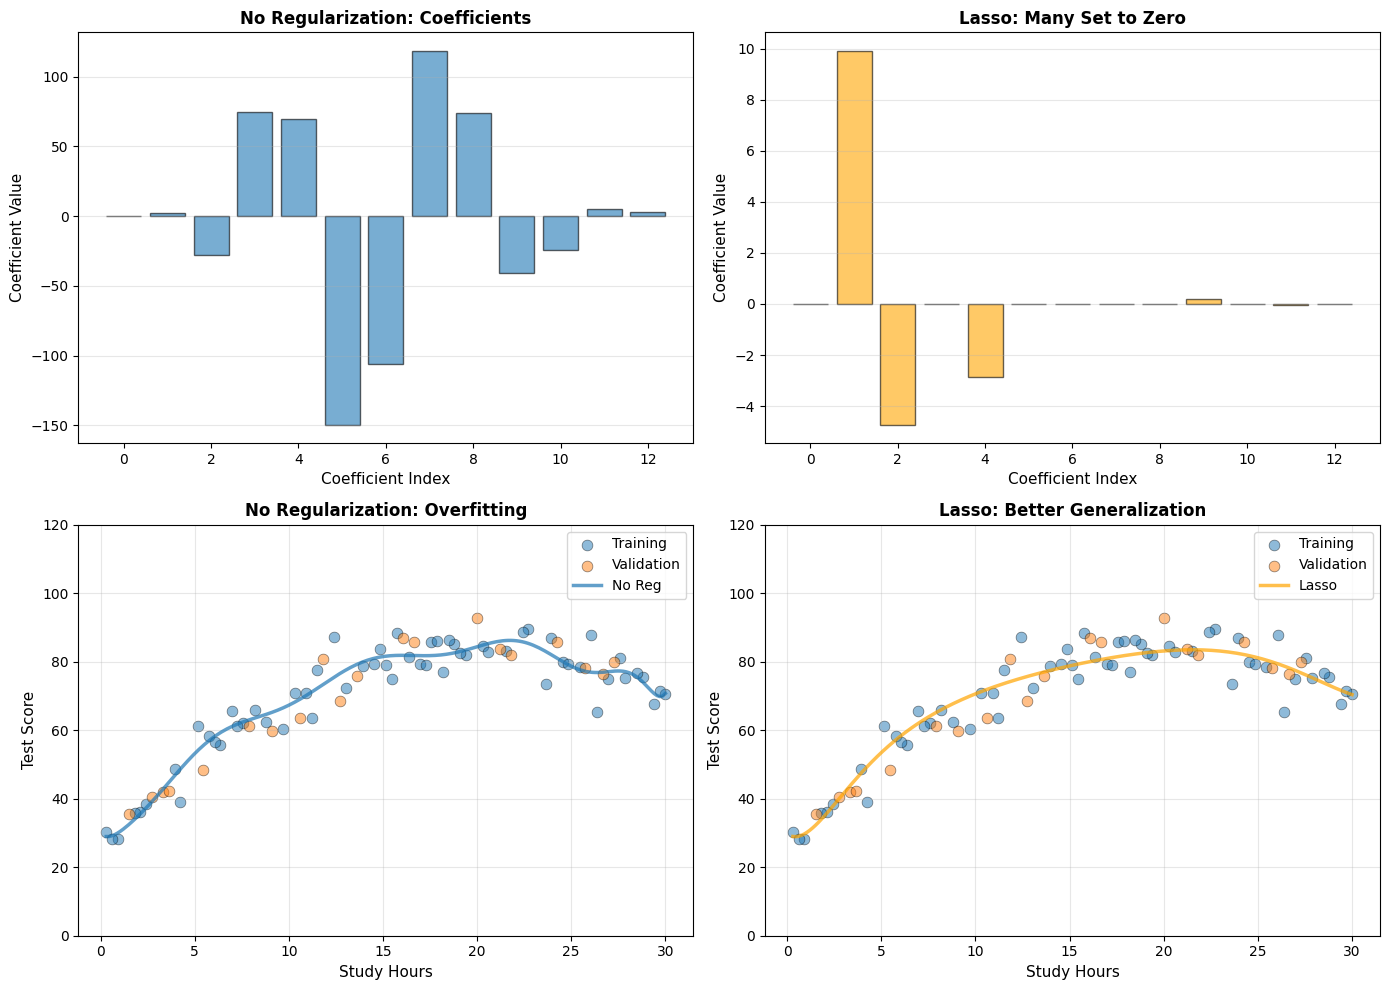

In [8]:
# Compare No Regularization vs Lasso
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot (1,1): No Regularization Coefficients
axes[0, 0].bar(range(len(model_overfit.coef_)), model_overfit.coef_, 
               alpha=0.6, label='No Regularization', edgecolor='black', linewidth=1)
axes[0, 0].set_xlabel('Coefficient Index', fontsize=11)
axes[0, 0].set_ylabel('Coefficient Value', fontsize=11)
axes[0, 0].set_title('No Regularization: Coefficients', fontsize=12, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3, axis='y')

# Plot (1,2): Lasso Coefficients
axes[0, 1].bar(range(len(lasso_model.coef_)), lasso_model.coef_, 
               alpha=0.6, label=f'Lasso (λ={lambda_value})', color='orange', edgecolor='black', linewidth=1)
axes[0, 1].set_xlabel('Coefficient Index', fontsize=11)
axes[0, 1].set_ylabel('Coefficient Value', fontsize=11)
axes[0, 1].set_title(f'Lasso: Many Set to Zero', fontsize=12, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Prepare prediction data
X_plot = np.linspace(X_train.min(), X_train.max(), 200).reshape(-1, 1)
X_plot_norm = (X_plot - X_mean) / X_std
X_plot_poly = poly.transform(X_plot_norm)

y_plot_overfit = model_overfit.predict(X_plot_poly)
y_plot_lasso = lasso_model.predict(X_plot_poly)

# Plot (2,1): No Regularization Predictions
axes[1, 0].scatter(X_train, y_train, alpha=0.5, s=60, label='Training', edgecolors='black', linewidths=0.5)
axes[1, 0].scatter(X_val, y_val, alpha=0.5, s=60, label='Validation', edgecolors='black', linewidths=0.5)
axes[1, 0].plot(X_plot, y_plot_overfit, '-', linewidth=2.5, label='No Reg', alpha=0.7)
axes[1, 0].set_xlabel('Study Hours', fontsize=11)
axes[1, 0].set_ylabel('Test Score', fontsize=11)
axes[1, 0].set_title('No Regularization: Overfitting', fontsize=12, fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].set_ylim([0, 120])

# Plot (2,2): Lasso Predictions
axes[1, 1].scatter(X_train, y_train, alpha=0.5, s=60, label='Training', edgecolors='black', linewidths=0.5)
axes[1, 1].scatter(X_val, y_val, alpha=0.5, s=60, label='Validation', edgecolors='black', linewidths=0.5)
axes[1, 1].plot(X_plot, y_plot_lasso, '-', linewidth=2.5, label='Lasso', alpha=0.7, color='orange')
axes[1, 1].set_xlabel('Study Hours', fontsize=11)
axes[1, 1].set_ylabel('Test Score', fontsize=11)
axes[1, 1].set_title('Lasso: Better Generalization', fontsize=12, fontweight='bold')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].set_ylim([0, 120])

plt.tight_layout()
plt.show()

**Key Observations:**

| Aspect | Ridge (L2) | Lasso (L1) |
|--------|-----------|-----------|
| **Penalty** | Sum of squared coefficients | Sum of absolute coefficients |
| **Effect on coefficients** | Shrinks all toward zero | Sets many exactly to zero |
| **Feature selection** | Keeps all features | Automatic feature selection |
| **When to use** | All features potentially relevant | Many irrelevant features suspected |
| **Model complexity** | Moderate reduction | Can be very sparse |
| **Interpretability** | All features contribute | Easier (fewer features) |

**When to choose which:**
- **Ridge:** When you believe most features contribute, just want to control their magnitude
- **Lasso:** When you want automatic feature selection and a simpler, more interpretable model
- **In practice:** Try both! Use validation set to decide which works better

## <a id='toc5_'></a>[Choosing the Regularization Strength (Lambda)](#toc0_)

The value of $\lambda$ (alpha in sklearn) is critical. Too small and you still overfit; too large and you underfit. How do we choose?

**Answer:** Use the validation set! (Just like we did for polynomial degree)

### <a id='toc5_1_'></a>[The Lambda Spectrum](#toc0_)

Let's explore how different values of $\lambda$ affect our model's performance and coefficients.

In [9]:
# Test different lambda values
lambdas = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]

print("Ridge Regression - Lambda Search:")
print("=" * 60)

ridge_results = []
for lam in lambdas:
    model = Ridge(alpha=lam)
    model.fit(X_train_poly, y_train)
    
    train_mse = mean_squared_error(y_train, model.predict(X_train_poly))
    val_mse = mean_squared_error(y_val, model.predict(X_val_poly))
    
    ridge_results.append({
        'lambda': lam,
        'train_mse': train_mse,
        'val_mse': val_mse,
        'coef': model.coef_.copy()
    })
    
    print(f"λ={lam:7.2f} | Train MSE: {train_mse:6.2f} | Val MSE: {val_mse:6.2f}")

# Find best lambda
best_ridge = min(ridge_results, key=lambda x: x['val_mse'])
print(f"\n{'='*60}")
print(f"🎯 Best Ridge λ: {best_ridge['lambda']} (Val MSE: {best_ridge['val_mse']:.2f})")
print("=" * 60)

Ridge Regression - Lambda Search:
λ=   0.01 | Train MSE:  20.12 | Val MSE:  21.44
λ=   0.03 | Train MSE:  20.32 | Val MSE:  21.66
λ=   0.10 | Train MSE:  20.45 | Val MSE:  22.11
λ=   0.30 | Train MSE:  20.58 | Val MSE:  22.83
λ=   1.00 | Train MSE:  21.10 | Val MSE:  24.73
λ=   3.00 | Train MSE:  22.73 | Val MSE:  29.03
λ=  10.00 | Train MSE:  26.56 | Val MSE:  37.86

🎯 Best Ridge λ: 0.01 (Val MSE: 21.44)


In [10]:
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)

In [11]:
print("\nLasso Regression - Lambda Search:")
print("=" * 60)

lasso_results = []
for lam in lambdas:
    model = Lasso(alpha=lam, max_iter=100000)
    model.fit(X_train_poly, y_train)
    
    train_mse = mean_squared_error(y_train, model.predict(X_train_poly))
    val_mse = mean_squared_error(y_val, model.predict(X_val_poly))
    n_zeros = np.sum(np.abs(model.coef_) < 1e-10)
    
    lasso_results.append({
        'lambda': lam,
        'train_mse': train_mse,
        'val_mse': val_mse,
        'n_zeros': n_zeros,
        'coef': model.coef_.copy()
    })
    
    print(f"λ={lam:7.2f} | Train MSE: {train_mse:6.2f} | Val MSE: {val_mse:6.2f} | Zeros: {n_zeros:2d}/{len(model.coef_)}")

# Find best lambda
best_lasso = min(lasso_results, key=lambda x: x['val_mse'])
print(f"\n{'='*60}")
print(f"🎯 Best Lasso λ: {best_lasso['lambda']} (Val MSE: {best_lasso['val_mse']:.2f})")
print("=" * 60)


Lasso Regression - Lambda Search:
λ=   0.01 | Train MSE:  20.47 | Val MSE:  21.84 | Zeros:  5/13
λ=   0.03 | Train MSE:  20.55 | Val MSE:  22.21 | Zeros:  6/13
λ=   0.10 | Train MSE:  20.97 | Val MSE:  23.62 | Zeros:  6/13
λ=   0.30 | Train MSE:  21.83 | Val MSE:  26.94 | Zeros:  7/13
λ=   1.00 | Train MSE:  28.64 | Val MSE:  40.82 | Zeros:  7/13
λ=   3.00 | Train MSE:  55.87 | Val MSE:  84.10 | Zeros:  8/13
λ=  10.00 | Train MSE:  90.71 | Val MSE: 143.78 | Zeros: 10/13

🎯 Best Lasso λ: 0.01 (Val MSE: 21.84)


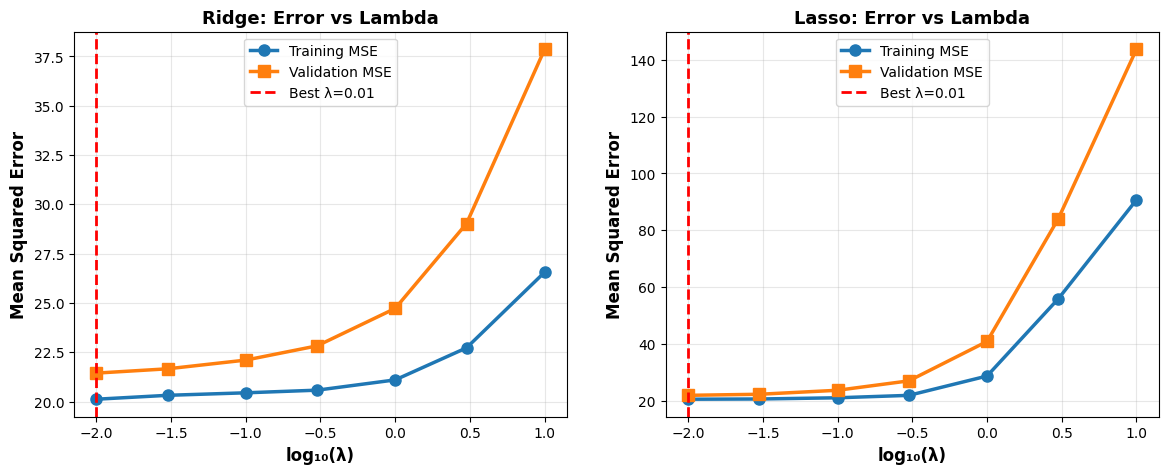

In [12]:
# Visualize the effect of lambda
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Ridge: Error vs Lambda
ridge_train_errors = [r['train_mse'] for r in ridge_results]
ridge_val_errors = [r['val_mse'] for r in ridge_results]
lambda_log = np.log10([l if l > 0 else 1e-3 for l in lambdas])

axes[0].plot(lambda_log, ridge_train_errors, 'o-', linewidth=2.5, markersize=8, label='Training MSE')
axes[0].plot(lambda_log, ridge_val_errors, 's-', linewidth=2.5, markersize=8, label='Validation MSE')
axes[0].axvline(np.log10(best_ridge['lambda']) if best_ridge['lambda'] > 0 else np.log10(1e-3), 
                color='red', linestyle='--', linewidth=2, label=f'Best λ={best_ridge["lambda"]}')
axes[0].set_xlabel('log₁₀(λ)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Mean Squared Error', fontsize=12, fontweight='bold')
axes[0].set_title('Ridge: Error vs Lambda', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# Lasso: Error vs Lambda
lasso_train_errors = [r['train_mse'] for r in lasso_results]
lasso_val_errors = [r['val_mse'] for r in lasso_results]

axes[1].plot(lambda_log, lasso_train_errors, 'o-', linewidth=2.5, markersize=8, label='Training MSE')
axes[1].plot(lambda_log, lasso_val_errors, 's-', linewidth=2.5, markersize=8, label='Validation MSE')
axes[1].axvline(np.log10(best_lasso['lambda']) if best_lasso['lambda'] > 0 else np.log10(1e-3), 
                color='red', linestyle='--', linewidth=2, label=f'Best λ={best_lasso["lambda"]}')
axes[1].set_xlabel('log₁₀(λ)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Mean Squared Error', fontsize=12, fontweight='bold')
axes[1].set_title('Lasso: Error vs Lambda', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.show()

## <a id='toc6_'></a>[Summary](#toc0_)

Congratulations! You've learned one of the most important techniques in machine learning: **regularization**.

**Key Takeaways:**

1. **The Problem:**
   - Complex models (high-degree polynomials, many features) tend to overfit
   - They memorize training noise instead of learning true patterns
   - Large coefficients enable wild oscillations and overfitting

2. **The Solution: Regularization**
   - Add a penalty term to the loss function that discourages large coefficients
   - Forces the model to balance fitting data AND staying simple
   - Controlled by hyperparameter $\lambda$ (or alpha in sklearn)

3. **Ridge Regression (L2):**
   - Penalty: $\lambda \sum \beta_j^2$ (sum of squared coefficients)
   - Effect: Shrinks all coefficients smoothly toward zero
   - Use when: Most features are relevant, just need to control magnitude
   - Result: All features contribute, none exactly eliminated

4. **Lasso Regression (L1):**
   - Penalty: $\lambda \sum |\beta_j|$ (sum of absolute coefficients)
   - Effect: Can set coefficients exactly to zero
   - Use when: Many features might be irrelevant
   - Result: Automatic feature selection, sparse models

5. **Choosing Lambda ($\lambda$):**
   - Too small: Underfitting (doesn't constrain complexity enough)
   - Too large: Overfitting (over-constrains, loses signal)
   - **Sweet spot:** Use validation set or cross-validation
   - Grid search is your friend!

6. **The Workflow:**
   ```python
   # 1. Create polynomial features
   poly = PolynomialFeatures(degree=12)
   X_poly = poly.fit_transform(X)
   
   # 2. Choose regularization method
   model = Ridge(alpha=0.1)  # or Lasso(alpha=0.1)
   
   # 4. Evaluate on test set
   test_mse = mean_squared_error(y_test, grid.predict(X_test))
   ```

**What's Next?**

Regularization is just one tool in your overfitting prevention toolkit. In future notebooks, we'll explore:
- **More regularization variants:** Elastic Net (combines L1 and L2)
- **Feature engineering:** Creating better features instead of just many features
- **Model selection:** Comparing different model types entirely
- **Ensemble methods:** Combining multiple models to improve generalization

**Practice Tips:**
- Always use a validation/test split to detect overfitting
- Start with simple models, add complexity only when needed
- Try both Ridge and Lasso—let the validation set decide
- Use grid search to find optimal hyperparameters
- Visualize your models to build intuition

**Remember:** The best model isn't the one that fits training data perfectly—it's the one that generalizes best to new data. Regularization helps you find that balance!
